# MM HW 04 Question 2 Part b

In [42]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

samples_1 = np.loadtxt("samples-hw4-2.txt")

def breit_wigner(x, M, Gamma, amplitude=1):
    y = (1/np.pi) * Gamma / ((x-M)**2 + Gamma**2)
    return amplitude * y

def breit_wigner_norm(x, M, Gamma, amplitude=1):
    integ, _ = quad(breit_wigner, 0, np.inf, args=(M, Gamma))
    return breit_wigner(x, M, Gamma, amplitude=amplitude) / integ

## Part i

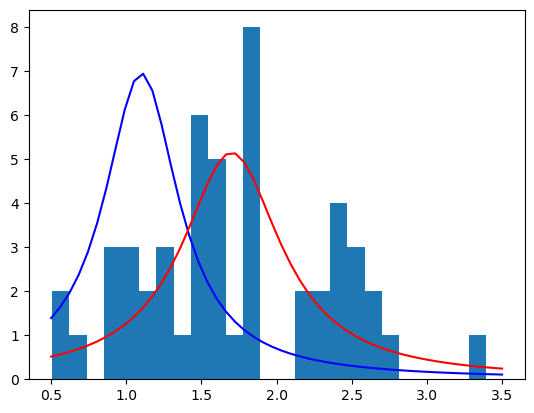

<Figure size 800x1200 with 0 Axes>

In [50]:
x = np.linspace(.5, 3.5, 50)
n_bins = 25
N = len(samples_1)
dx = (3.5-.5)/n_bins

# Given Variables
a0_M = 1.1
a0_Gamma = 0.3

a1_M = 1.7
a1_Gamma = 0.4

# Using the Functions
a0_overlay = breit_wigner_norm(x, a0_M, a0_Gamma)
a1_overlay = breit_wigner_norm(x, a1_M, a1_Gamma)
a0_overlay *= N * dx
a1_overlay *= N * dx

plt.plot(x, a0_overlay, label='a0', color="b")
plt.plot(x, a1_overlay, label='a1', color="r")
plt.hist(samples_1, bins=n_bins)
plt.figure(figsize=(8, 12))
plt.show()

## Part ii

(array([[0., 0., 0., 1., 1., 0., 1., 1., 2., 0., 0., 4., 0., 0., 2., 1.,
         0., 1., 1., 0., 0., 0., 0., 0., 0.],
        [2., 1., 0., 2., 2., 2., 2., 0., 4., 5., 1., 4., 0., 0., 0., 1.,
         4., 2., 1., 1., 0., 0., 0., 0., 1.]]),
 array([0.50568193, 0.62120834, 0.73673476, 0.85226118, 0.96778759,
        1.08331401, 1.19884042, 1.31436684, 1.42989325, 1.54541967,
        1.66094609, 1.7764725 , 1.89199892, 2.00752533, 2.12305175,
        2.23857816, 2.35410458, 2.469631  , 2.58515741, 2.70068383,
        2.81621024, 2.93173666, 3.04726307, 3.16278949, 3.2783159 ,
        3.39384232]),
 <a list of 2 BarContainer objects>)

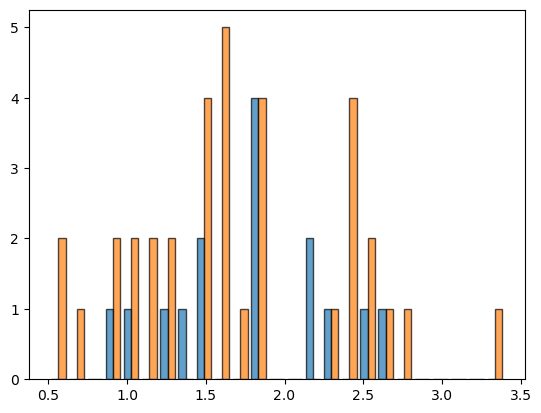

In [54]:
dec = a0_overlay > a1_overlay

mask = dec.astype(bool)
plt.hist([samples_1[mask], samples_1[~mask]],
         bins=n_bins,
         density=False,
         alpha=.7,
         edgecolor='black',
         label=[r"$H_0$", r"$H_1$"])

## Part iii

In [55]:
a0_count = np.sum(dec)
a1_count = np.sum(~dec)

print("a0:", a0_count)
print("a1:", a1_count)

a0: 15
a1: 35


## Conclusion:

This shows that a1 minimized posteior risk because it's distribtion has the highest probability to be sampled from. So my decision if I had to choose would be a1. I believe that this is visually the correct choice because the distribution for a1 overlaps a lot more with the data ie the mean of that function visually looks more accurate, while the amplitude is a bit small I would still choose that one over the a0 distribution's overlap. I am wondering if this is way connection is valid or not.